In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "dengue_weekly.csv",
    parse_dates=["start_date", "end_date"],
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26753 entries, 0 to 26752
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   year        26753 non-null  int64         
 1   week        26753 non-null  int64         
 2   start_date  26753 non-null  datetime64[us]
 3   end_date    26753 non-null  datetime64[us]
 4   district    26753 non-null  str           
 5   cases       26753 non-null  int64         
dtypes: datetime64[us](2), int64(3), str(1)
memory usage: 1.2 MB


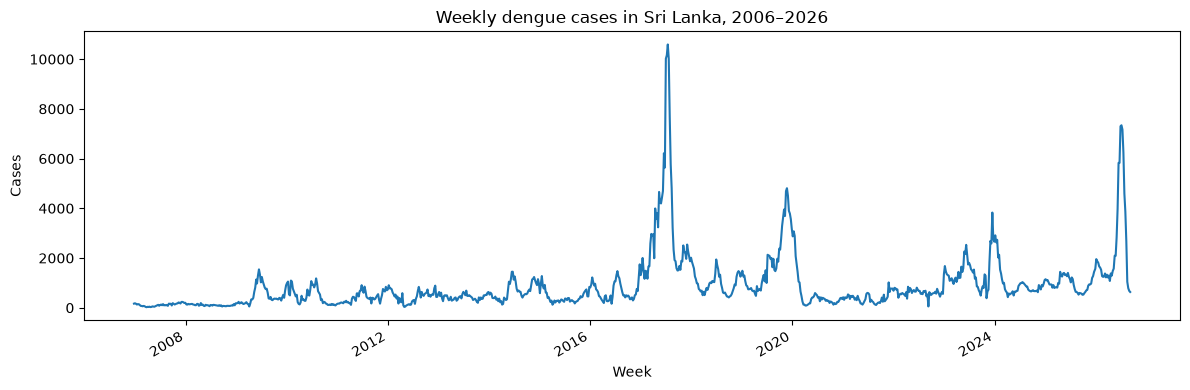

In [2]:
national = df.groupby("start_date")["cases"].sum()

fig, ax = plt.subplots(figsize=(12, 4))
national.plot(ax=ax)
ax.set_title("Weekly dengue cases in Sri Lanka, 2006–2026")
ax.set_xlabel("Week")
ax.set_ylabel("Cases")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_national_weekly_cases.png", dpi=150)
plt.show()

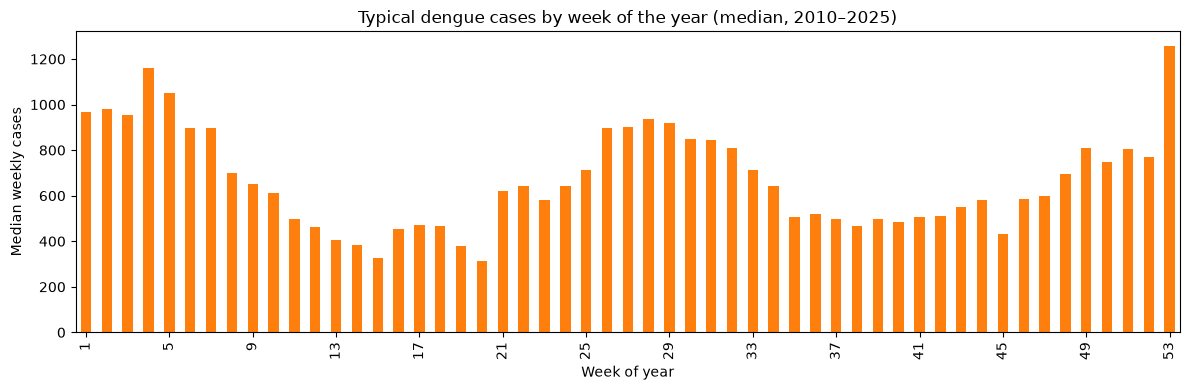

In [3]:
national_week = df.groupby(["year", "week"])["cases"].sum().reset_index()
national_week = national_week[national_week["year"].between(2010, 2025)]
season = national_week.groupby("week")["cases"].median()

fig, ax = plt.subplots(figsize=(12, 4))
season.plot(kind="bar", ax=ax, color="tab:orange")
ax.set_title("Typical dengue cases by week of the year (median, 2010–2025)")
ax.set_xlabel("Week of year")
ax.set_ylabel("Median weekly cases")
ax.set_xticks(range(0, len(season), 4))
ax.set_xticklabels(season.index[::4])
fig.tight_layout()
fig.savefig(FIG_DIR / "02_seasonality_by_week.png", dpi=150)
plt.show()

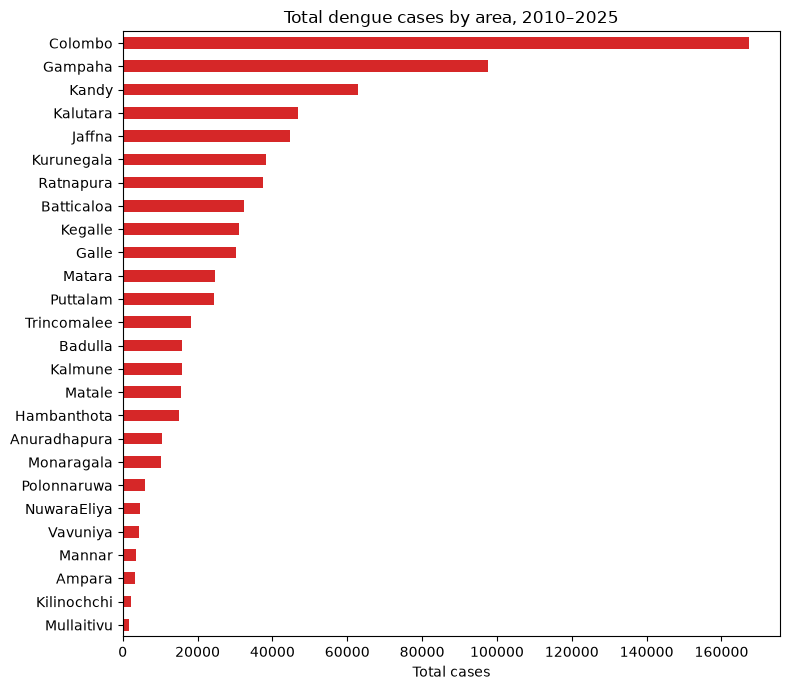

In [4]:
by_area = (
    df[df["year"].between(2010, 2025)]
    .groupby("district")["cases"]
    .sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 7))
by_area.plot(kind="barh", ax=ax, color="tab:red")
ax.set_title("Total dengue cases by area, 2010–2025")
ax.set_xlabel("Total cases")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_cases_by_area.png", dpi=150)
plt.show()

In [5]:
share = (by_area / by_area.sum() * 100).round(1)
share.sort_values(ascending=False).head(5)

district
Colombo     21.9
Gampaha     12.8
Kandy        8.2
Kalutara     6.1
Jaffna       5.8
Name: cases, dtype: float64

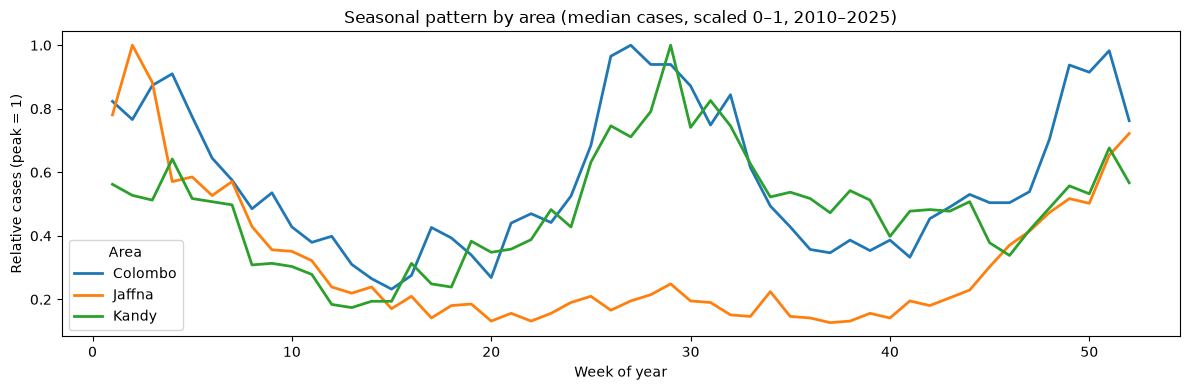

In [6]:
areas = ["Colombo", "Kandy", "Jaffna"]
sub = df[
    df["year"].between(2010, 2025)
    & df["district"].isin(areas)
    & (df["week"] <= 52)
]
profile = sub.groupby(["district", "week"])["cases"].median().unstack(0)
profile = profile / profile.max()

fig, ax = plt.subplots(figsize=(12, 4))
profile.plot(ax=ax, linewidth=2)
ax.set_title("Seasonal pattern by area (median cases, scaled 0–1, 2010–2025)")
ax.set_xlabel("Week of year")
ax.set_ylabel("Relative cases (peak = 1)")
ax.legend(title="Area")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_seasonality_by_area.png", dpi=150)
plt.show()

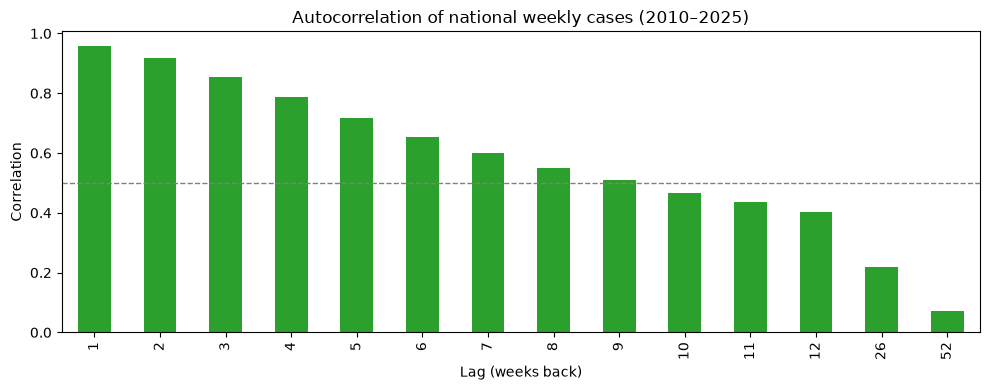

1     0.96
2     0.92
3     0.85
4     0.79
5     0.72
6     0.65
7     0.60
8     0.55
9     0.51
10    0.47
11    0.44
12    0.40
26    0.22
52    0.07
dtype: float64

In [7]:
national_10_25 = national[national.index.year.isin(range(2010, 2026))]
lags = list(range(1, 13)) + [26, 52]
acf = pd.Series({lag: national_10_25.autocorr(lag) for lag in lags})

fig, ax = plt.subplots(figsize=(10, 4))
acf.plot(kind="bar", ax=ax, color="tab:green")
ax.set_title("Autocorrelation of national weekly cases (2010–2025)")
ax.set_xlabel("Lag (weeks back)")
ax.set_ylabel("Correlation")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_autocorrelation.png", dpi=150)
plt.show()
acf.round(2)